In [ ]:
import torch
from PIL import Image
from transformers import AutoProcessor

from trace import TensorTrace
from weights import count_parameters, load_detector

model = "google/owlv2-base-patch16-ensemble"
queries = ["a cat", "a remote control"]
image_path = "cat.jpeg"

threshold = 0.1

print(f"Loading {model} (assets: {image_path})")
detector, config = load_detector(model)
processor = AutoProcessor.from_pretrained(model)

print(f"CLIP vision parameters: {count_parameters(detector.clip.vision):,}")
print(f"CLIP text parameters: {count_parameters(detector.clip.text):,}")
print(
    f"Detection heads: "
    f"{count_parameters(detector.class_head) + count_parameters(detector.box_head) + count_parameters(detector.objectness_head):,}"
)

pil_image = Image.open(image_path).convert("RGB")
inputs = processor(text=[queries], images=pil_image, return_tensors="pt")
trace = TensorTrace(enabled=True)
with torch.inference_mode():
    outputs = detector(
        input_ids=inputs["input_ids"],
        pixel_values=inputs["pixel_values"],
        attention_mask=inputs.get("attention_mask"),
        trace=trace,
    )

target_sizes = torch.tensor([pil_image.size[::-1]])
results = processor.post_process_grounded_object_detection(
    outputs,
    threshold=threshold,
    target_sizes=target_sizes,
    text_labels=[queries],
)[0]
print("\nDetections")
if len(results["scores"]) == 0:
    print(f"  none above threshold {threshold}")
for score, label, box in zip(results["scores"], results["text_labels"], results["boxes"]):
    box = [round(value, 1) for value in box.tolist()]
    print(f"  {label}  score={score.item():.3f}  box={box}")


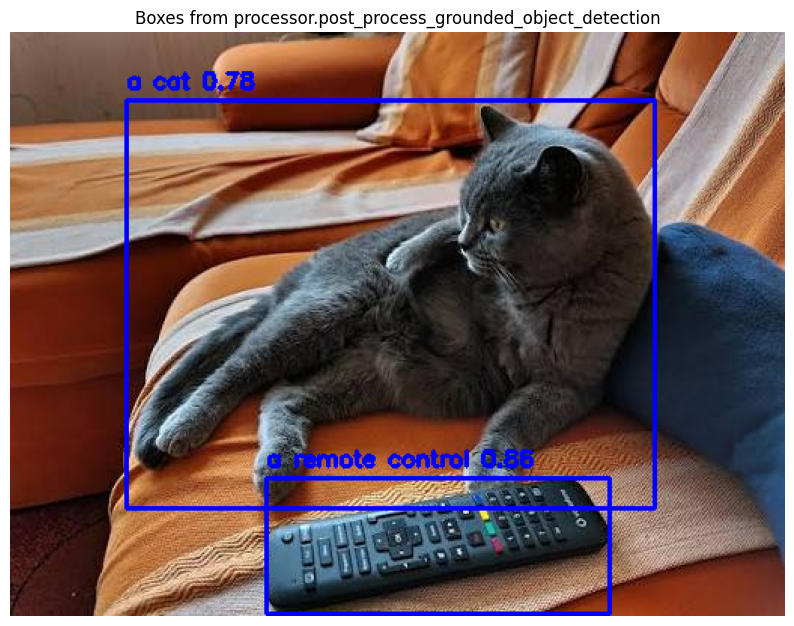

In [ ]:
import matplotlib.pyplot as plt
import cv2

image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
canvas = image_rgb.copy()

for score, label, box in zip(results["scores"], results["text_labels"], results["boxes"]):
    x1, y1, x2, y2 = [int(v) for v in box.tolist()]
    cv2.rectangle(canvas, (x1, y1), (x2, y2), (0, 0, 255), 2)
    cv2.putText(
        canvas,
        f"{label} {score.item():.2f}",
        (x1, max(y1 - 8, 0)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (0, 0, 255),
        2,
    )

plt.figure(figsize=(10, 8))
plt.imshow(canvas)
plt.axis("off")
plt.title("Detection's results")
plt.show()


## Data processing

The **image** is padded to the maximum size (`max(height, width)`) and then resize into image 960x960, the paddings are applied to the right and bottom. As a result, we have 3601 tokenes which 3600 (960 / 16, 960 - image size, 16 - patch size of the CLIP) - image tokens, 1 - class token (used to multiply to the image token to merge patch and global feature information). Implementation is [here](https://github.com/huggingface/transformers/blob/main/src/transformers/models/owlv2/image_processing_pil_owlv2.py#L424).

The text is passed through CLIPTextModel and at the end we just take the last token `<EOS>` as a feature which aggregated the whole context of the given sentence.

Both features are used to generate bounding boxes, objectness score, logits.

## Feature postprocessing

Each token patch is used to predict the single object with the following output (features size dim=4) `(cx, cy, w, h)`, normalized to `[0, 1]`, decoded as `sigmoid(box_head(token) + box_bias[cell])`. `token` - is offset from the patch position and size of it. `box_bias` is the reversed sigmoid position of the patch itself in the grid `(cx, cy)` and reversed size of the patch and the final output would be normalized output.

In [11]:
"""Feature to pixel bounding boxes.

Raw tensors (cell 0):

logits          [B, num_patches, num_queries] - class match per patch x query
pred_boxes      [B, num_patches, 4]           - cx, cy, w, h (normalized)
objectness_logits [B, num_patches]            - whether there is an object

"""

from transformers.image_transforms import center_to_corners_format

print(f"logits {tuple(outputs.logits.shape)}")
print(f"pred_boxes {tuple(outputs.pred_boxes.shape)}  (cx, cy, w, h normalized)")
print(f"objectness_logits {tuple(outputs.objectness_logits.shape)}  (ignored by grounded post-process)\n")

# 1. one score and one query index per patch
# Take the text query with the largest logit on each patch.
best_logits, best_query_ix = outputs.logits.max(dim=-1)  # [B, num_patches]
scores_all = torch.sigmoid(best_logits)
print(
    f"After max(dim=-1) over queries: scores_all {tuple(scores_all.shape)}, "
    f"labels_all {tuple(best_query_ix.shape)}"
)
print(f"Patches with score > {threshold}: {int((scores_all[0] > threshold).sum())} / {scores_all.shape[1]}\n")

# 2. box format [cx, cy, w, h] -> [x1, y1, x2, y2]
boxes_corners = center_to_corners_format(outputs.pred_boxes)
print(f"After center_to_corners_format: {tuple(boxes_corners.shape)}\n")

# 3. Normalized output -> original image pixels size
height, width = pil_image.size[1], pil_image.size[0]
max_size = max(height, width)
boxes_pixels = boxes_corners * max_size
print(f"Original image (H, W) = ({height}, {width}), scale = max(H, W) = {max_size}\n")

# 4. Threshold filter
keep = scores_all[0] > threshold
manual_scores = scores_all[0, keep]
manual_labels = best_query_ix[0, keep]
manual_boxes = boxes_pixels[0, keep]
print(f"After threshold {threshold}: {manual_boxes.shape[0]} detections\n")

for score, qix, box in zip(manual_scores, manual_labels, manual_boxes):
    box = [round(float(v), 1) for v in box.tolist()]
    print(f"{queries[int(qix)]}  score={score.item():.3f}  box={box}")

# 5. Text labels
manual_text_labels = [queries[int(i)] for i in manual_labels]

# Manual check to HF's output
# ref_scores = results["scores"]
# ref_boxes = results["boxes"]
# ref_labels = results["text_labels"]
# if len(manual_scores) == len(ref_scores):
#     score_diff = (manual_scores - ref_scores).abs().max().item()
#     box_diff = (manual_boxes - ref_boxes).abs().max().item()
#     print(f"\nMatches processor: score max |diff| {score_diff:.3e}, box max |diff| {box_diff:.3e}")
#     print(f"Same text labels: {manual_text_labels == ref_labels}")
# else:
#     print(f"\nCount mismatch: manual {len(manual_scores)} vs processor {len(ref_scores)}")

# 6. Objectness score
obj_probs = torch.sigmoid(outputs.objectness_logits[0])
print(f"\nObjectness {int((obj_probs > 0.5).sum())} patches above 0.5")


logits (1, 3600, 2)
pred_boxes (1, 3600, 4)  (cx, cy, w, h normalized)
objectness_logits (1, 3600)  (ignored by grounded post-process)

After max(dim=-1) over queries: scores_all (1, 3600), labels_all (1, 3600)
Patches with score > 0.1: 2 / 3600

After center_to_corners_format: (1, 3600, 4)

Original image (H, W) = (388, 515), scale = max(H, W) = 515

After threshold 0.1: 2 detections

a cat  score=0.778  box=[77.2, 45.7, 428.5, 316.6]
a remote control  score=0.863  box=[170.1, 296.4, 399.0, 386.0]

Objectness 2 patches above 0.5


## Training notes about box parameterization


1. **One box per patch token - not offsets.** Each of the 3600 patch tokens predicts
  exactly one box, shared by all text queries. The raw MLP output is `(cx, cy, w, h)`.
2. **The patch is its own anchor.** `box_bias[cell]` is the *reversed sigmoid* of the
  cell's center `(cx, cy)` plus a one-patch size `(w, h)`. So whenever the MLP
  outputs ~0, the predicted box defaults to a one-patch box centered exactly on that
  token's cell. The network only learns a residual correction in logit space; after
  training those corrections are substantial, so the bias is the starting point, not the prediction itself.
3. **Training matched predictions to ground truth, then regressed these boxes.**
  DETR-style bipartite (Hungarian) matching assigns each GT box to one of the 3600
  patch predictions; the loss is focal loss on the class similarity plus
  `L1 + GIoU` on the normalized `(cx, cy, w, h)` boxes. OWLv2 additionally
  self-trains on web images with model-generated pseudo-labels, but the box
  parameterization is the one decoded below.

Coordinate biases:

1. **Geometric prior.** A patch token describes the region around its own cell, so
   its box should be centered there by default. The bias bakes that in; the MLP
   starts from a sane anchor everywhere on the grid.
2. **Sigmoid would otherwise saturate.** Coordinates must stay in `[0, 1]`. If the
   MLP had to produce the final logit from scratch, boxes that must move far from
   their cell - or sit near the border, where sigmoid saturates - would train
   slowly. A near-zero residual on top of the prior keeps gradients well-behaved.
3. **Uniform parameterization.** Centers and sizes are all decoded the same way
   (`sigmoid(bias + delta)`), so one loss (`L1 + GIoU` on `cx, cy, w, h`) covers
   both translation and scale.

grid 60x60 = 3600 patch tokens, one anchor box each
prior cx range: [0.0168, 0.9999]   (1-based cell centers)
prior cy range: [0.0168, 0.9999]
prior w = h  =  0.0168   (= 1/60, one patch)

prior cx, first row of the grid: [0.016763320192694664, 0.03342665731906891, 0.050089988857507706, 0.0667533203959465, 0.083416648209095, 0.1000799685716629]

Trained box_head correction |delta| (logit space):
  mean 1.767   p50 1.430   p95 4.845   max 8.858
sigmoid(delta + bias) == outputs.pred_boxes: True

2 winning patches; anchor (cell-center) box -> final box:
patch 1527  anchor=(0.467,0.433,0.017,0.017)-> final=(0.491,0.352,0.682,0.526)
patch 2436  anchor=(0.617,0.683,0.017,0.017)-> final=(0.552,0.663,0.444,0.174)


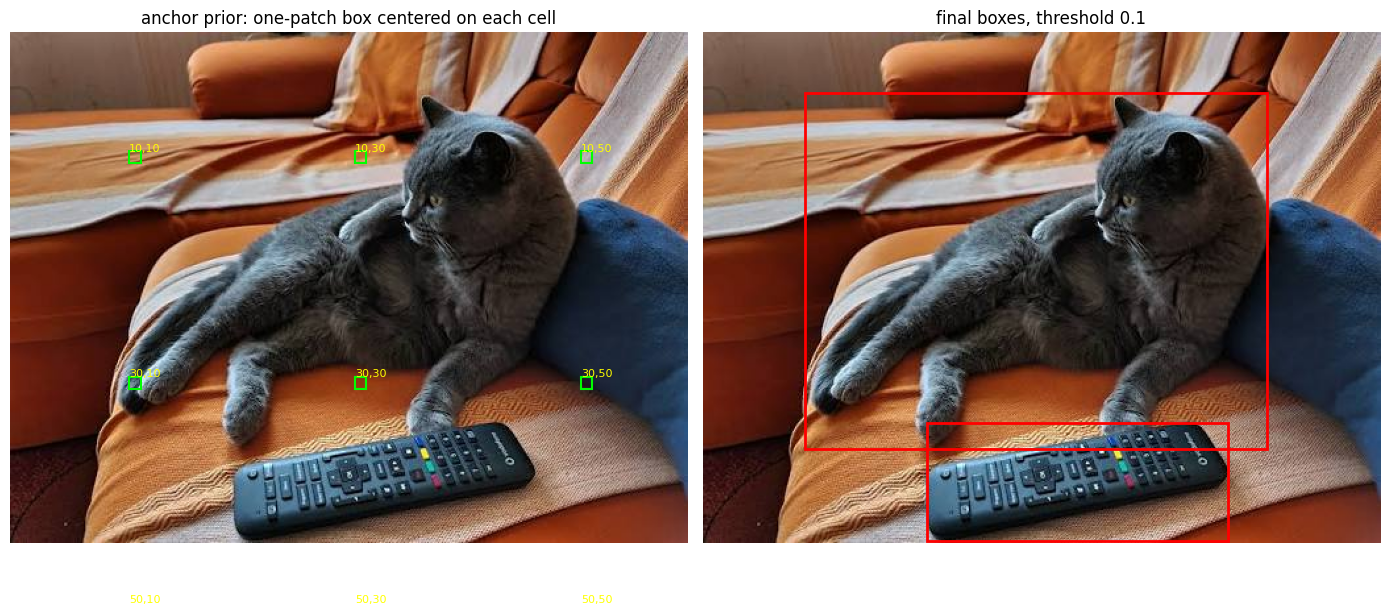

In [12]:
"""Decode the box coordinate bias and measure the MLP's correction.

detector.py computes:  pred_boxes = sigmoid(box_head(token) + box_bias[cell])
This cell shows what the bias alone decodes to (the "zero-correction" default)
and how far the trained MLP actually moves away from that default.
"""

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import torch

from heads.box_bias import grid_box_bias

grid = detector.grid_size                       # 60 -> 60 x 60 = 3600 patch tokens
bias = grid_box_bias(grid, grid)                # [3600, 4] reversed-sigmoid ("logit") space
prior = torch.sigmoid(bias)                     # [3600, 4] default cx, cy, w, h per cell

print(f"grid {grid}x{grid} = {grid * grid} patch tokens, one anchor box each")
print(f"prior cx range: [{prior[:, 0].min():.4f}, {prior[:, 0].max():.4f}]   (1-based cell centers)")
print(f"prior cy range: [{prior[:, 1].min():.4f}, {prior[:, 1].max():.4f}]")
print(f"prior w = h  =  {prior[0, 2]:.4f}   (= 1/{grid}, one patch)")
print(f"\nprior cx, first row of the grid: {prior[:, 0].reshape(grid, grid)[0, :6].tolist()}")

# --- the trained MLP correction, in the same logit space ---
feats = outputs.image_embeds.reshape(1, grid * grid, -1)
with torch.inference_mode():
    delta = detector.box_head(feats)[0]         # [3600, 4] what the MLP adds on top of the bias

d = delta.abs()
print("\nTrained box_head correction |delta| (logit space):")
print(f"  mean {d.mean():.3f}   p50 {d.median():.3f}   p95 {d.quantile(0.95):.3f}   max {d.max():.3f}")

rebuilt = torch.sigmoid(delta + bias.to(delta.device))
print(f"sigmoid(delta + bias) == outputs.pred_boxes: {torch.allclose(rebuilt, outputs.pred_boxes[0], atol=1e-5)}")

# --- winning patches: anchor (cell center) vs final box ---
best_logits = outputs.logits[0].max(dim=-1).values
keep = torch.sigmoid(best_logits) > threshold
print(f"\n{int(keep.sum())} winning patches; anchor (cell-center) box -> final box:")
for p in torch.nonzero(keep).flatten():
    a = prior[p]
    f = outputs.pred_boxes[0, p]
    print(
        f"patch {p.item():4d}  anchor=({a[0]:.3f},{a[1]:.3f},{a[2]:.3f},{a[3]:.3f})"
        f"-> final=({f[0]:.3f},{f[1]:.3f},{f[2]:.3f},{f[3]:.3f})"
    )

# --- draw the anchor prior and the final boxes ---
W, H = pil_image.size
max_size = max(W, H)   # same convention as the post-process cell above

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(pil_image)
axes[0].set_title("anchor prior: one-patch box centered on each cell")
for row in (10, 30, 50):
    for col in (10, 30, 50):
        cx, cy, w, h = prior[row * grid + col].tolist()
        x0, y0 = (cx - w / 2) * W, (cy - h / 2) * max_size
        axes[0].add_patch(mpatches.Rectangle((x0, y0), w * max_size, h * max_size,
                                             fill=False, edgecolor="lime", linewidth=1.5))
        axes[0].text(x0, y0, f"{row},{col}", color="yellow", fontsize=8)
axes[0].axis("off")

axes[1].imshow(pil_image)
axes[1].set_title(f"final boxes, threshold {threshold}")
for box in results["boxes"]:
    x1, y1, x2, y2 = box.tolist()
    axes[1].add_patch(mpatches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                         fill=False, edgecolor="red", linewidth=2))
axes[1].axis("off")

plt.tight_layout()
plt.show()